In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
# Dataset directory
DATA_PATH = Path("../csv_source_files")

# Load fertilizer dataset
fertilizer_df = pd.read_csv(
    DATA_PATH / "12_chemical_fertilizer_sales_yearly.csv"
)

# Load gdp_commodity_contribution dataset
gdp_df = pd.read_csv(
    DATA_PATH / "13_agriculture_gdp_commodity_contribution_2024_25.csv"
)

print("Fertilizer and GDP datasets loaded successfully!")

Fertilizer and GDP datasets loaded successfully!


In [4]:
print("Fertilizer Dataset:")
display(fertilizer_df.head())
fertilizer_df.info()

print("\nGDP Dataset:")
display(gdp_df.head())
gdp_df.info()


Fertilizer Dataset:


,Fiscal_Year,Urea_Mt,DAP_Mt,Potash_Mt,Total_ICL_STCL_Mt
0,2024/25,270151,154439,16715,441305
1,2023/24,259542,184046,14730,58318
2,2022/23,226148,110120,6455,342723
3,2021/22,143482,77720,6633,27836
4,2020/21,225180,140982,12990,379152


<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Fiscal_Year        15 non-null     str  
 1   Urea_Mt            15 non-null     int64
 2   DAP_Mt             15 non-null     int64
 3   Potash_Mt          15 non-null     int64
 4   Total_ICL_STCL_Mt  15 non-null     int64
dtypes: int64(4), str(1)
memory usage: 732.0 bytes

GDP Dataset:


,Commodity,Percentage_Contribution_to_Agriculture_GDP
0,RICE PADDY (NOT HUSKED),12.82
1,VEGETABLES,14.47
2,MAIZE (CORN),6.64
3,POTATOES,6.56
4,WHEAT,5.88


<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 2 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Commodity                                   93 non-null     str    
 1   Percentage_Contribution_to_Agriculture_GDP  93 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.6 KB


### Fertilizer Analysis


In [5]:
# Available fiscal years
print("\nFISCAL YEARS")
print(sorted(fertilizer_df["Fiscal_Year"].unique()))


FISCAL YEARS
['2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']


In [6]:
# Missing and Duplicate Values
print("\n Missing and Duplicate Values in Fertilizer Dataset:")
print(fertilizer_df.isnull().sum())
print(fertilizer_df.duplicated().sum())


 Missing and Duplicate Values in Fertilizer Dataset:
Fiscal_Year          0
Urea_Mt              0
DAP_Mt               0
Potash_Mt            0
Total_ICL_STCL_Mt    0
dtype: int64
0


In [11]:
# Yearly Total Sales
total_sales_per_year=pd.DataFrame({'Fiscal_Year': fertilizer_df['Fiscal_Year'], 'Total_Sales': fertilizer_df['Potash_Mt'] + fertilizer_df['DAP_Mt'] + fertilizer_df['Urea_Mt'], 'Given_Total_Sales': fertilizer_df['Total_ICL_STCL_Mt']})
total_sales_per_year

,Fiscal_Year,Total_Sales,Given_Total_Sales
0,2024/25,441305,441305
1,2023/24,458318,58318
2,2022/23,342723,342723
3,2021/22,227835,27836
4,2020/21,379152,379152
5,2019/20,394595,394595
6,2018/19,344003,344004
7,2017/18,348734,348734
8,2016/17,328218,328217
9,2015/16,327520,327520


In [12]:
fertilizer_yearly = total_sales_per_year.sort_values(
    "Fiscal_Year"
).reset_index(drop=True)

display(fertilizer_yearly)

,Fiscal_Year,Total_Sales,Given_Total_Sales
0,2010/11,110013,110013
1,2011/12,144814,44813
2,2012/13,176963,176963
3,2013/14,232188,232189
4,2014/15,298676,298677
5,2015/16,327520,327520
6,2016/17,328218,328217
7,2017/18,348734,348734
8,2018/19,344003,344004
9,2019/20,394595,394595


In [13]:
highest_sales = fertilizer_yearly.loc[
    fertilizer_yearly["Total_Sales"].idxmax()
]

lowest_sales = fertilizer_yearly.loc[
    fertilizer_yearly["Total_Sales"].idxmin()
]

print("Highest Sales:")
display(highest_sales)

print("Lowest Sales:")
display(lowest_sales)

Highest Sales:


Fiscal_Year          2023/24
Total_Sales           458318
Given_Total_Sales      58318
Name: 13, dtype: object

Lowest Sales:


Fiscal_Year          2010/11
Total_Sales           110013
Given_Total_Sales     110013
Name: 0, dtype: object

In [15]:
initial_sales = fertilizer_yearly["Total_Sales"].iloc[0]
latest_sales = fertilizer_yearly["Total_Sales"].iloc[-1]

print("Initial Sales:", initial_sales)
print("Latest Sales:", latest_sales)

absolute_change = latest_sales - initial_sales

percentage_change = (
    absolute_change / initial_sales
) * 100

print("Absolute Change:", absolute_change)
print("Percentage Change:", round(percentage_change, 2), "%")

Initial Sales: 110013
Latest Sales: 441305
Absolute Change: 331292
Percentage Change: 301.14 %


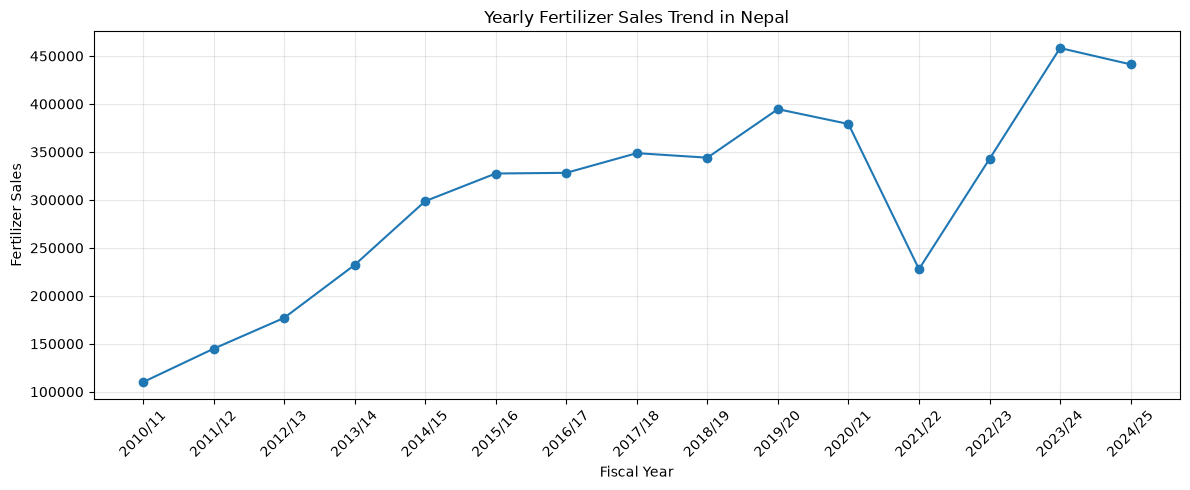

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    fertilizer_yearly["Fiscal_Year"],
    fertilizer_yearly["Total_Sales"],
    marker="o"
)

plt.title("Yearly Fertilizer Sales Trend in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Fertilizer Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Total Sales by Fertilizer Type
fertilizer_type_sales = (
    fertilizer_df[
        ["Urea_Mt", "DAP_Mt", "Potash_Mt"]
    ].sum()
    .reset_index()
)

fertilizer_type_sales.columns = ["Fertilizer_Type", "Total_Sales"]

fertilizer_type_sales = fertilizer_type_sales.sort_values(
    "Total_Sales", ascending=False
)

display(fertilizer_type_sales)

,Fertilizer_Type,Total_Sales
0,Urea_Mt,2846214
1,DAP_Mt,1590226
2,Potash_Mt,118617


In [ ]:
# Contribution of Fertilizer Types to Total Sales
fertilizer_type_sales["Contribution_%"] = (
    fertilizer_type_sales["Total_Sales"]
    / fertilizer_type_sales["Total_Sales"].sum()
) * 100

display(fertilizer_type_sales.round(2))

,Fertilizer_Type,Total_Sales,Contribution_%
0,Urea_Mt,2846214,62.48
1,DAP_Mt,1590226,34.91
2,Potash_Mt,118617,2.60


In [ ]:
# Highest and Lowest Contributor
display(fertilizer_type_sales.iloc[[0, -1]])

,Fertilizer_Type,Total_Sales,Contribution_%
0,Urea_Mt,2846214,62.484707
2,Potash_Mt,118617,2.604073


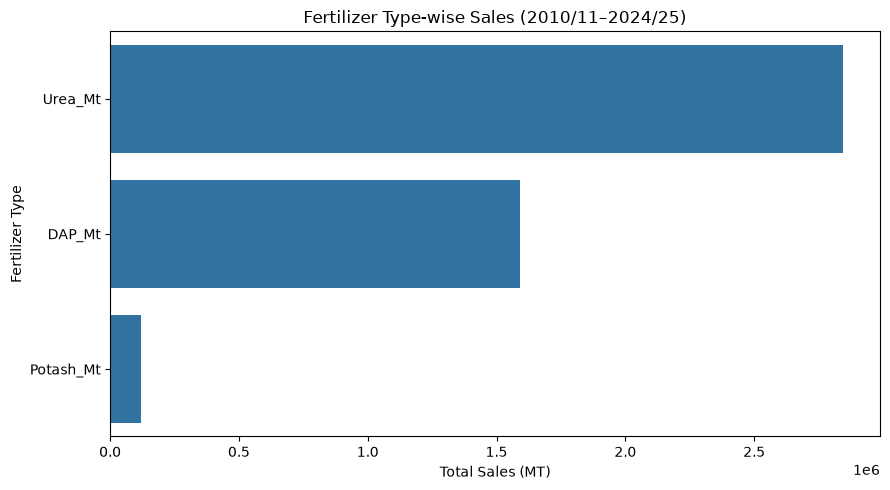

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fertilizer_type_sales,
    x="Total_Sales",
    y="Fertilizer_Type"
)

plt.title("Fertilizer Type-wise Sales (2010/11–2024/25)")
plt.xlabel("Total Sales (MT)")
plt.ylabel("Fertilizer Type")
plt.tight_layout()
plt.show()

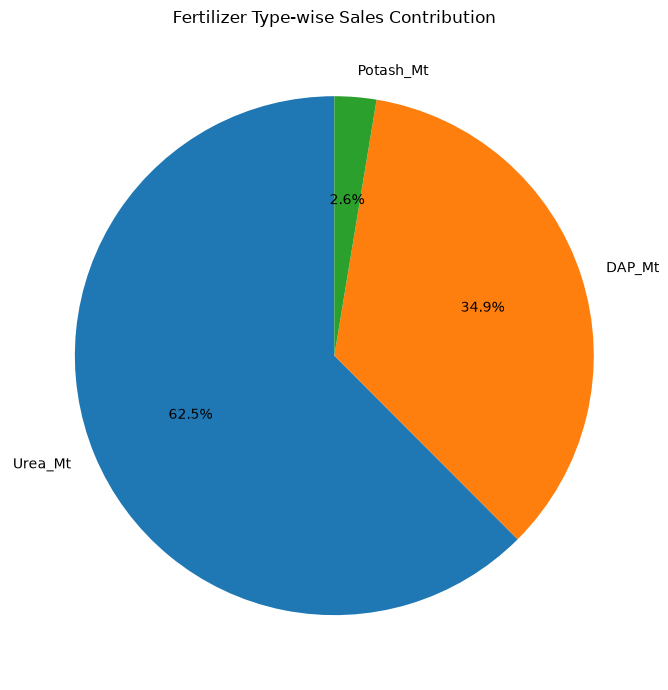

In [26]:
plt.figure(figsize=(7, 7))

plt.pie(
    fertilizer_type_sales["Total_Sales"],
    labels=fertilizer_type_sales["Fertilizer_Type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Fertilizer Type-wise Sales Contribution")
plt.tight_layout()
plt.show()

In [27]:
# Year-wise Analysis
fertilizer_growth = fertilizer_df[
    ["Fiscal_Year", "Urea_Mt", "DAP_Mt", "Potash_Mt"]
].copy()

# Calculate combined sales
fertilizer_growth["Calculated_Total_Mt"] = (
    fertilizer_growth["Urea_Mt"]
    + fertilizer_growth["DAP_Mt"]
    + fertilizer_growth["Potash_Mt"]
)

# Sort chronologically
fertilizer_growth = fertilizer_growth.sort_values(
    "Fiscal_Year"
).reset_index(drop=True)

display(fertilizer_growth)

,Fiscal_Year,Urea_Mt,DAP_Mt,Potash_Mt,Calculated_Total_Mt
0,2010/11,85191,22001,2821,110013
1,2011/12,97957,43146,3711,144814
2,2012/13,108553,65722,2688,176963
3,2013/14,145622,81520,5046,232188
4,2014/15,190163,101797,6716,298676
5,2015/16,213063,107121,7336,327520
6,2016/17,205425,114802,7991,328218
7,2017/18,235304,105619,7811,348734
8,2018/19,215733,120893,7377,344003
9,2019/20,224700,160298,9597,394595


In [ ]:
# YoY growth percentage
growth_columns = [
    "Urea_Mt",
    "DAP_Mt",
    "Potash_Mt",
    "Calculated_Total_Mt"
]

fertilizer_yoy_growth = fertilizer_growth[
    ["Fiscal_Year"] + growth_columns
].copy()

fertilizer_yoy_growth[growth_columns] = (
    fertilizer_yoy_growth[growth_columns].pct_change() * 100
)

display(fertilizer_yoy_growth.round(2))

,Fiscal_Year,Urea_Mt,DAP_Mt,Potash_Mt,Calculated_Total_Mt
0,2010/11,NaN,NaN,NaN,NaN
1,2011/12,14.99,96.11,31.55,31.63
2,2012/13,10.82,52.32,-27.57,22.20
3,2013/14,34.15,24.04,87.72,31.21
4,2014/15,30.59,24.87,33.10,28.64
5,2015/16,12.04,5.23,9.23,9.66
6,2016/17,-3.58,7.17,8.93,0.21
7,2017/18,14.54,-8.00,-2.25,6.25
8,2018/19,-8.32,14.46,-5.56,-1.36
9,2019/20,4.16,32.59,30.09,14.71


In [29]:
for column in growth_columns:
    highest = fertilizer_yoy_growth.loc[
        fertilizer_yoy_growth[column].idxmax()
    ]

    lowest = fertilizer_yoy_growth.loc[
        fertilizer_yoy_growth[column].idxmin()
    ]

    print(f"\n{column}")
    print(
        f"Highest Growth: {highest[column]:.2f}% "
        f"({highest['Fiscal_Year']})"
    )
    print(
        f"Lowest Growth: {lowest[column]:.2f}% "
        f"({lowest['Fiscal_Year']})"
    )


Urea_Mt
Highest Growth: 57.61% (2022/23)
Lowest Growth: -36.28% (2021/22)

DAP_Mt
Highest Growth: 96.11% (2011/12)
Lowest Growth: -44.87% (2021/22)

Potash_Mt
Highest Growth: 128.20% (2023/24)
Lowest Growth: -48.94% (2021/22)

Calculated_Total_Mt
Highest Growth: 50.43% (2022/23)
Lowest Growth: -39.91% (2021/22)


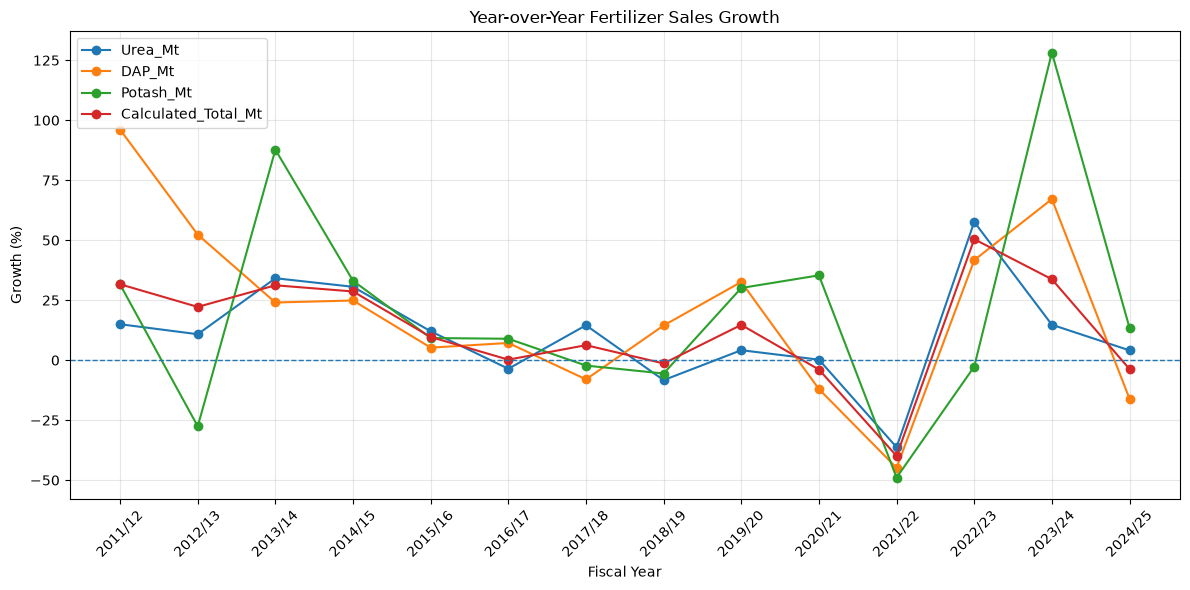

In [30]:
plt.figure(figsize=(12, 6))

for column in growth_columns:
    plt.plot(
        fertilizer_yoy_growth["Fiscal_Year"],
        fertilizer_yoy_growth[column],
        marker="o",
        label=column
    )

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Year-over-Year Fertilizer Sales Growth")
plt.xlabel("Fiscal Year")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
fertilizer_contribution = fertilizer_growth[
    ["Fiscal_Year", "Urea_Mt", "DAP_Mt", "Potash_Mt"]
].copy()

fertilizer_columns = ["Urea_Mt", "DAP_Mt", "Potash_Mt"]

yearly_total = fertilizer_contribution[fertilizer_columns].sum(axis=1)

fertilizer_contribution[fertilizer_columns] = (
    fertilizer_contribution[fertilizer_columns]
    .div(yearly_total, axis=0) * 100
)

display(fertilizer_contribution.round(2))

,Fiscal_Year,Urea_Mt,DAP_Mt,Potash_Mt
0,2010/11,77.44,20.00,2.56
1,2011/12,67.64,29.79,2.56
2,2012/13,61.34,37.14,1.52
3,2013/14,62.72,35.11,2.17
4,2014/15,63.67,34.08,2.25
5,2015/16,65.05,32.71,2.24
6,2016/17,62.59,34.98,2.43
7,2017/18,67.47,30.29,2.24
8,2018/19,62.71,35.14,2.14
9,2019/20,56.94,40.62,2.43


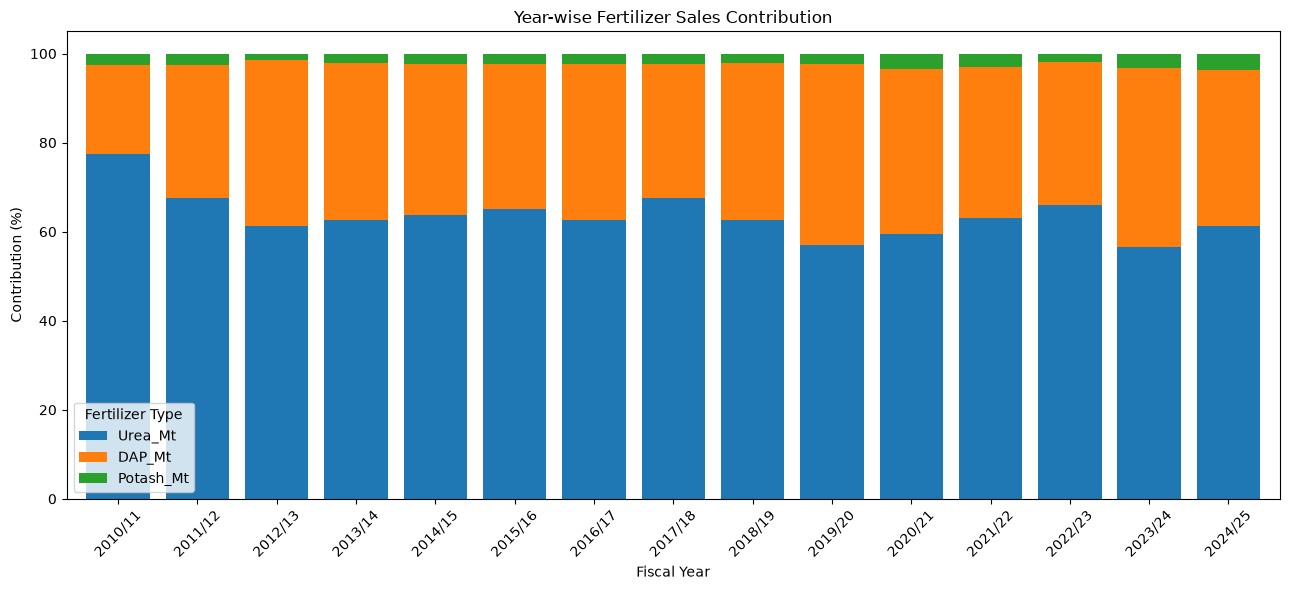

In [33]:
fertilizer_contribution.set_index("Fiscal_Year")[
    ["Urea_Mt", "DAP_Mt", "Potash_Mt"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

plt.title("Year-wise Fertilizer Sales Contribution")
plt.xlabel("Fiscal Year")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=45)
plt.legend(title="Fertilizer Type")
plt.tight_layout()
plt.show()

## Key Findings – Chemical Fertilizer Analysis

### 1. Overall Fertilizer Sales Trend
- Calculated fertilizer sales increased from **110,013 MT in 2010/11** to **441,305 MT in 2024/25**.
- This represents an overall increase of **301.14%** over the 15-year period.
- The highest annual sales were recorded in **2023/24 (458,318 MT)**, followed by a decline to 441,305 MT in 2024/25.

### 2. Fertilizer Type-wise Contribution
- **Urea** was the dominant fertilizer, accounting for approximately **62.48%** of cumulative sales.
- **DAP** contributed approximately **34.91%**.
- **Potash** accounted for approximately **2.60%**.
- Urea and DAP together represented approximately 97.40% of the combined sales of these three fertilizer types.

### 3. Year-over-Year Growth
- The highest growth in combined fertilizer sales occurred in **2022/23 (50.43%)**.
- The largest decline occurred in **2021/22 (-39.91%)**.
- Urea recorded its highest growth in 2022/23 (57.61%).
- DAP recorded its highest growth in 2011/12 (96.11%).
- Potash recorded its highest growth in 2023/24 (128.20%).

### 4. Data Quality Observations
- The calculated yearly totals were obtained by summing Urea, DAP and Potash sales.
- Several discrepancies were identified in the original `Total_ICL_STCL_Mt` values when compared with the calculated totals.
- The `Given_Total_Sales` values also contained apparent missing digits and minor differences in some fiscal years.
- Therefore, the fertilizer analysis uses calculated Urea, DAP and Potash totals and excludes the unreliable ICL/STCL figures.

**Note:** All contribution percentages represent cumulative sales across the 15 fiscal years, not the contribution in a single fiscal year.

### 5. Year-wise Fertilizer Contribution
- Urea consistently maintained the largest share of annual fertilizer sales throughout the 15-year period.
- DAP remained the second-largest contributor, while Potash accounted for the smallest share.
- The yearly contribution analysis highlights changes in the composition of fertilizer sales rather than just changes in total sales volume.
- Comparing annual shares helps identify whether the relative importance of Urea, DAP and Potash has shifted over time.

### GDP Analysis


In [34]:
# Dataset dimensions
print("Dataset Shape:", gdp_df.shape)

# Dataset information
gdp_df.info()

# Check missing values
print("\nMissing Values:")
display(gdp_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", gdp_df.duplicated().sum())

# Check unique commodities
print("\nUnique Commodities:", gdp_df["Commodity"].nunique())

# Statistical summary
display(gdp_df["Percentage_Contribution_to_Agriculture_GDP"].describe())

Dataset Shape: (93, 2)
<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 2 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Commodity                                   93 non-null     str    
 1   Percentage_Contribution_to_Agriculture_GDP  93 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.6 KB

Missing Values:


Commodity                                     0
Percentage_Contribution_to_Agriculture_GDP    0
dtype: int64


Duplicate Records: 1

Unique Commodities: 90


count     93.000000
mean       3.115269
std       12.640920
min        0.000000
25%        0.020000
50%        0.110000
75%        1.040000
max      100.000000
Name: Percentage_Contribution_to_Agriculture_GDP, dtype: float64

In [35]:
# Display all commodity names containing TOTAL
display(
    gdp_df[
        gdp_df["Commodity"].str.contains(
            "TOTAL", case=False, na=False
        )
    ].sort_values("Commodity")
)

,Commodity,Percentage_Contribution_to_Agriculture_GDP
92,AGRICULTURE TOTAL WITH FORESTRY,100.00
66,CROPS TOTAL,65.80
91,FISHERY TOTAL,1.56
90,FORESTRY TOTAL,8.71
89,LIVESTOCK TOTAL,23.92


In [36]:
# Remove zero values and unwanted aggregate rows
gdp_clean_df = gdp_df[
    (gdp_df["Percentage_Contribution_to_Agriculture_GDP"] > 0) &
    (~gdp_df["Commodity"].str.strip().isin([
        "AGRICULTURE TOTAL WITH FORESTRY",
        "CROPS TOTAL",
        "LIVESTOCK TOTAL"
    ]))
].drop_duplicates().copy()

# Verify cleaned dataset
print("Original Shape:", gdp_df.shape)
print("Cleaned Shape:", gdp_clean_df.shape)

display(gdp_clean_df.head())

Original Shape: (93, 2)
Cleaned Shape: (78, 2)


,Commodity,Percentage_Contribution_to_Agriculture_GDP
0,RICE PADDY (NOT HUSKED),12.82
1,VEGETABLES,14.47
2,MAIZE (CORN),6.64
3,POTATOES,6.56
4,WHEAT,5.88


In [37]:
print("Zero Contributions:",
      (gdp_clean_df["Percentage_Contribution_to_Agriculture_GDP"] == 0).sum())

print("Duplicate Records:", gdp_clean_df.duplicated().sum())

print("Remaining Total Categories:")
display(
    gdp_clean_df[
        gdp_clean_df["Commodity"].str.contains(
            "TOTAL", case=False, na=False
        )
    ]
)

Zero Contributions: 0
Duplicate Records: 0
Remaining Total Categories:


,Commodity,Percentage_Contribution_to_Agriculture_GDP
90,FORESTRY TOTAL,8.71
91,FISHERY TOTAL,1.56


In [38]:
gdp_column = "Percentage_Contribution_to_Agriculture_GDP"

display(gdp_clean_df[gdp_column].describe().round(2))

count    78.00
mean      1.28
std       2.73
min       0.01
25%       0.05
50%       0.16
75%       1.04
max      14.47
Name: Percentage_Contribution_to_Agriculture_GDP, dtype: float64

In [39]:
total_contribution = gdp_clean_df[gdp_column].sum()

print("Total Commodity Contribution:", round(total_contribution, 2), "%")

Total Commodity Contribution: 100.0 %


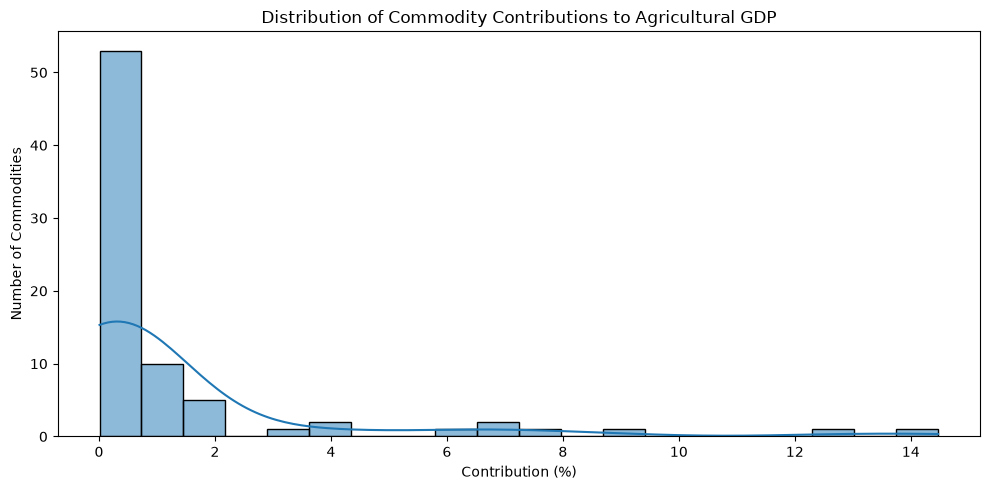

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=gdp_clean_df,
    x=gdp_column,
    bins=20,
    kde=True
)

plt.title("Distribution of Commodity Contributions to Agricultural GDP")
plt.xlabel("Contribution (%)")
plt.ylabel("Number of Commodities")
plt.tight_layout()
plt.show()

In [41]:
top_10_commodities = (
    gdp_clean_df
    .sort_values(
        "Percentage_Contribution_to_Agriculture_GDP",
        ascending=False
    )
    .head(10)
)

display(top_10_commodities)

,Commodity,Percentage_Contribution_to_Agriculture_GDP
1,VEGETABLES,14.47
0,RICE PADDY (NOT HUSKED),12.82
90,FORESTRY TOTAL,8.71
67,RAW MILK OF BUFFALO,7.69
2,MAIZE (CORN),6.64
3,POTATOES,6.56
4,WHEAT,5.88
69,RAW MILK OF CATTLE,4.14
68,BUFFALO MEAT,4.03
70,GOATS,3.27


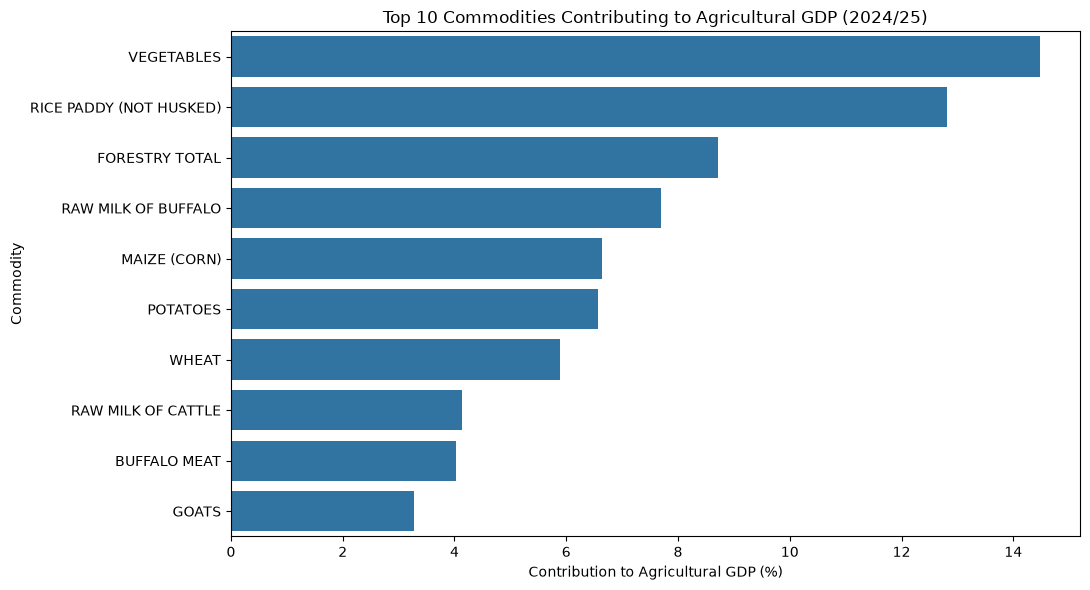

In [42]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_commodities,
    x="Percentage_Contribution_to_Agriculture_GDP",
    y="Commodity"
)

plt.title("Top 10 Commodities Contributing to Agricultural GDP (2024/25)")
plt.xlabel("Contribution to Agricultural GDP (%)")
plt.ylabel("Commodity")
plt.tight_layout()
plt.show()

In [43]:
top_10_contribution = top_10_commodities[
    "Percentage_Contribution_to_Agriculture_GDP"
].sum()

print("Top 10 Combined Contribution:", round(top_10_contribution, 2), "%")

Top 10 Combined Contribution: 74.21 %


In [44]:
bottom_10_commodities = (
    gdp_clean_df
    .sort_values(
        "Percentage_Contribution_to_Agriculture_GDP",
        ascending=True
    )
    .head(10)
)

display(bottom_10_commodities)

,Commodity,Percentage_Contribution_to_Agriculture_GDP
57,"COFFEE, GREEN",0.01
56,OTHER POME FRUITS AND STONE FRUITS,0.01
84,"SHORN WOOL, GREASY, INCLUDING FLEECE-WASHED SH...",0.01
83,OSTRICHES AND EMUS,0.01
82,"RAW MILK OF SHEEP, GOATS",0.01
78,"OTHER EGGS FROM OTHER BIRDS IN SHELL, FRESH",0.01
81,DUCKS,0.01
80,OTHER BIRDS (PIGEON),0.01
53,APRICOTS,0.02
88,EXCRETA OF ANIMALS USEFUL FOR MANURE/ FERTILIZ...,0.02


## Key Findings – Agricultural GDP Commodity Contribution (2024/25)

### 1. Overall Contribution
- The cleaned dataset contains 78 records after removing zero-contribution entries, unwanted aggregate categories and duplicates.
- The retained commodity and category contributions sum to 100%.

### 2. Top Contributors
- Vegetables recorded the highest contribution to Agricultural GDP at **14.47%**, followed by Rice Paddy (Not Husked) at **12.82%**.
- Forestry Total contributed **8.71%**, while Raw Milk of Buffalo contributed **7.69%**.
- The ten highest-ranked recorded categories accounted for a combined **74.21%** of the total contribution.

### 3. Bottom Contributors
- Several commodities recorded very small contributions of **0.01%**, including Green Coffee, Ducks, Ostriches and Emus, and other minor categories.
- Apricots and Excreta of Animals Useful for Manure/Fertilizer each contributed **0.02%**.

### 4. Key Observation
- The contribution distribution shows that a relatively small group of recorded categories accounts for a large share of Agricultural GDP.
- Vegetables and rice are the two largest individual commodity contributors in the dataset.

**Note:** Forestry Total and Fishery Total were retained. Forestry Total is an aggregate category, so combined rankings should be interpreted with this classification in mind. The analysis represents the 2024/25 dataset only.